# LENDING CLUB

# OTIMIZAÇÃO DA CARTEIRA DE CRÉDITO

Este notebook constitui a **segunda etapa** da abordagem *predict-then-optimize*. Na primeira etapa (notebook 03), um modelo de scorecard estimou a probabilidade de default (PD) de cada solicitante e filtrou os 73.047 clientes elegíveis. Agora, de posse dessas estimativas, resolvemos o problema de decisão que é o cerne da Pesquisa Operacional: dado um capital limitado, **a quais clientes elegíveis conceder crédito** de modo a maximizar o retorno esperado da carteira, respeitando limites de risco e de diversificação.

Trata-se de um problema de **programação linear inteira binária** (0-1): para cada contrato decide-se, de forma discreta, conceder ou não o empréstimo. A estrutura é a de um *knapsack* multidimensional, em que o capital é o recurso escasso e cada empréstimo compete por ele com base na sua contribuição ao lucro e no seu consumo de capital e de risco.

# 1. IMPORTANDO BIBLIOTECAS

A otimização usa a biblioteca PuLP com o solver CBC. A célula abaixo garante a versão 2.x do PuLP — a 4.x mudou a API e não traz solver embutido. Se o PuLP já tiver sido carregado em outra versão nesta sessão, reinicie o kernel e execute novamente a partir daqui.

In [10]:
# --- Preparação do ambiente: garante PuLP 2.x (API clássica + solver CBC) ---
import subprocess, sys

def _pulp_classico():
    try:
        import pulp
        return hasattr(pulp, 'PULP_CBC_CMD') and hasattr(pulp.LpVariable, 'dicts')
    except Exception:
        return False

if not _pulp_classico():
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pulp==2.8.0'], check=False)
    for _m in [k for k in list(sys.modules) if k == 'pulp' or k.startswith('pulp.')]:
        del sys.modules[_m]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.figsize'] = (10, 5)
print('PuLP', pulp.__version__)

PuLP 2.8.0


# 2. CONJUNTO DE DADOS

Carregamos a base de clientes elegíveis exportada pelo notebook 03. Cada linha é um contrato candidato, identificado por `id_cliente`, com o valor e as condições do empréstimo, a classificação de risco (`grade`), a finalidade (`purpose`) e, sobretudo, a probabilidade de default (`PD`) estimada pelo modelo.

In [11]:
clientes = pd.read_parquet('dados/clientes_elegiveis.parquet')
print(f'Contratos elegíveis: {len(clientes):,}')
print(f'id_cliente único? {clientes["id_cliente"].is_unique}')
clientes.head()

Contratos elegíveis: 73,047
id_cliente único? True


,id_cliente,loan_amnt,int_rate,term,installment,grade,purpose,annual_inc,PD,score,default
0,373063,10525,12.99,36,354.58,C,credit_card,"45,000.00",0.09,508.37,0
1,373064,18000,6.03,36,547.84,A,debt_consolidation,"91,100.00",0.04,562.25,0
2,373066,29850,14.99,36,"1,034.62",C,home_improvement,"65,000.00",0.10,502.86,0
3,373067,12000,8.39,36,378.20,A,home_improvement,"140,000.00",0.03,588.80,0
4,373069,12000,16.99,60,298.17,D,credit_card,"48,000.00",0.15,476.08,0


# 3. RETORNO E PERDA ESPERADA

Para otimizar a carteira é preciso traduzir cada contrato em uma contribuição monetária esperada. Definimos três quantidades por empréstimo $i$:

1. **Juros totais contratados** ($j_i$), o que a instituição recebe além do principal caso o empréstimo seja integralmente honrado. A parcela mensal (`installment`) é fixada no contrato no momento da originação e pode ser reconstruída exatamente pela fórmula de amortização a partir de `loan_amnt`, `int_rate` e `term`; é, portanto, informação disponível na hora da decisão de conceder ou não, e não um valor realizado depois. O total que o tomador se compromete a pagar, se cumprir o contrato até o fim, é $\text{installment}_i \times \text{term}_i$, e os juros totais contratados são esse valor menos o principal $v_i$ (`loan_amnt`):

$$j_i = \text{installment}_i \times \text{term}_i - v_i$$

2. **Perda em caso de default**, modelada como $\text{LGD} \times v_i$, em que LGD (*Loss Given Default*) é a fração do principal perdida. Adotamos $\text{LGD} = 1$, hipótese conservadora que supõe a perda integral do principal e ignora pagamentos feitos antes do default e eventuais recuperações. O valor é um parâmetro e pode ser ajustado.

3. **Lucro esperado** ($\ell_i$), que pondera os dois cenários pela probabilidade de default estimada:

$$\ell_i = (1 - PD_i)\, j_i - PD_i \cdot \text{LGD} \cdot v_i$$

É $\ell_i$ que o modelo busca maximizar. Note que ele já incorpora o risco estimado na primeira etapa: dois empréstimos de mesmo valor e mesma taxa têm lucros esperados diferentes se seus PD diferem.

In [12]:
LGD = 1.0   # perda dado o default (fração do principal); 1.0 = perda integral

# 'installment' é a parcela contratual? Reconstruímos pela fórmula de amortização
# (Price) a partir de loan_amnt, int_rate e term — grandezas definidas na originação.
r = clientes['int_rate'] / 100 / 12
n = clientes['term']
parcela_contratual = clientes['loan_amnt'] * r * (1 + r)**n / ((1 + r)**n - 1)
dif = (clientes['installment'] - parcela_contratual).abs()
print(f'installment vs parcela da fórmula de amortização: '
      f'diferença mediana R$ {dif.median():.2f}; {(dif < 1).mean():.1%} dos contratos com diferença < R$ 1.')
print('Confirma que installment é a parcela contratual, fixada na originação (disponível na decisão),')
print('e não um valor realizado após a concessão.\n')

# Juros totais contratados e lucro esperado
clientes['juros'] = clientes['installment'] * clientes['term'] - clientes['loan_amnt']
clientes['lucro_esp'] = (1 - clientes['PD']) * clientes['juros'] - clientes['PD'] * LGD * clientes['loan_amnt']

print(f"Demanda total de capital:       R$ {clientes['loan_amnt'].sum():,.0f}")
print(f"Juros totais contratados:       R$ {clientes['juros'].sum():,.0f}")
print(f"Lucro esperado agregado:        R$ {clientes['lucro_esp'].sum():,.0f}")
print(f"Contratos com lucro esperado positivo: {(clientes['lucro_esp'] > 0).mean():.1%}")
clientes[['loan_amnt', 'int_rate', 'PD', 'juros', 'lucro_esp']].describe().round(2)

installment vs parcela da fórmula de amortização: diferença mediana R$ 0.00; 100.0% dos contratos com diferença < R$ 1.
Confirma que installment é a parcela contratual, fixada na originação (disponível na decisão),
e não um valor realizado após a concessão.

Demanda total de capital:       R$ 1,086,703,975
Juros totais contratados:       R$ 282,639,035
Lucro esperado agregado:        R$ 164,578,017
Contratos com lucro esperado positivo: 99.8%


,loan_amnt,int_rate,PD,juros,lucro_esp
count,"73,047.00","73,047.00","73,047.00","73,047.00","73,047.00"
mean,"14,876.78",11.83,0.09,"3,869.28","2,253.04"
std,"8,691.03",3.42,0.04,"3,681.13","2,534.16"
min,"1,000.00",6.00,0.01,95.12,"-1,378.41"
25%,"8,000.00",9.17,0.05,"1,346.12",581.37
50%,"13,000.00",11.99,0.08,"2,462.52","1,178.51"
75%,"20,000.00",13.98,0.12,"5,198.40","3,068.14"
max,"35,000.00",26.06,0.16,"27,862.60","22,196.45"


Praticamente todos os contratos elegíveis têm lucro esperado positivo, o que é consequência direta do filtro de PD aplicado na etapa anterior. Isso tem uma implicação importante para a otimização: **sem uma restrição de capital, a solução trivial seria conceder crédito a quase todos**. É o orçamento limitado que transforma o problema em uma decisão de alocação não trivial, na qual os empréstimos competem pelo capital escasso.

# 4. FORMULAÇÃO DO MODELO

Antes da notação matemática, a ideia em linguagem simples. Para cada um dos 73.047 contratos há uma decisão de **tudo ou nada**: concede-se o empréstimo pelo valor integral solicitado ou recusa-se, sem financiar apenas uma parte. O modelo escolhe quais conceder para **obter o maior lucro esperado possível**, obedecendo a cinco regras que um gestor de crédito imporia.

1. **Não gastar mais do que o caixa disponível.** O total emprestado não passa do orçamento de capital (aqui, 80% da demanda).
2. **Não deixar capital ocioso.** O total emprestado tem de atingir ao menos uma fração mínima do orçamento (aqui, 60%), para que o capital captado seja de fato aplicado.
3. **Não deixar a carteira arriscada demais.** O PD médio, ponderado pelo valor de cada empréstimo, não passa de um teto (aqui, 8%).
4. **Não concentrar demais em uma classe de risco.** Nenhuma `grade` (A a G) fica com mais do que uma fatia do orçamento (aqui, 30%).
5. **Respeitar um teto próprio para cada finalidade.** Cada `purpose` tem um limite explícito de participação no orçamento, definido na seção de parâmetros, o que impede, por exemplo, que a consolidação de dívida domine a carteira.

A seguir, as mesmas regras em notação formal.

**Conjuntos.** $C$ é o conjunto dos contratos elegíveis; $G$, o das classes de risco; $P$, o das finalidades.

**Variável de decisão.** Para cada contrato $i \in C$:

$$x_i = \begin{cases} 1, & \text{concede o empréstimo } i \text{ pelo valor integral} \\ 0, & \text{recusa} \end{cases}$$

**Parâmetros.** $v_i$ (valor), $\ell_i$ (lucro esperado) e $PD_i$ de cada contrato; $B$ (orçamento de capital); $u$ (utilização mínima); $\pi$ (teto de risco médio); $\kappa_g$ e $\kappa_p$ (tetos de concentração por grade e por finalidade).

**Função objetivo** — obter o maior lucro esperado:

$$\max \; \sum_{i \in C} \ell_i \, x_i$$

**Restrições.**

$$\textbf{(1) Orçamento máximo:}\quad \sum_{i \in C} v_i \, x_i \;\le\; B$$

$$\textbf{(2) Utilização mínima:}\quad \sum_{i \in C} v_i \, x_i \;\ge\; u \, B$$

$$\textbf{(3) Risco médio:}\quad \underbrace{\frac{\sum_{i} PD_i \, v_i \, x_i}{\sum_{i} v_i \, x_i}}_{\text{PD médio da carteira}} \;\le\; \pi \quad\Longleftrightarrow\quad \sum_{i} (PD_i - \pi)\, v_i \, x_i \;\le\; 0$$

$$\textbf{(4) Diversificação por grade:}\quad \sum_{i \in g} v_i \, x_i \;\le\; \kappa_g \, B \quad \forall\, g \in G$$

$$\textbf{(5) Diversificação por finalidade:}\quad \sum_{i \in p} v_i \, x_i \;\le\; \kappa_p \, B \quad \forall\, p \in P$$

$$\textbf{(6) Decisão tudo ou nada:}\quad x_i \in \{0, 1\} \quad \forall\, i \in C$$

A regra (3) parece uma média, mas o rearranjo mostrado à direita a transforma em uma desigualdade linear. As regras (4) e (5) são escritas como fatias do orçamento fixo $B$, mantendo o lado direito constante. E a regra (6), ao exigir que $x_i$ seja 0 ou 1, é exatamente o que proíbe o financiamento parcial: não há meio-empréstimo.

# 5. PARÂMETROS DO MODELO

Os parâmetros abaixo definem a política de crédito, calibrados para que as restrições sejam ativas sem tornar o problema inviável:

1. **Orçamento máximo** de 80% da demanda total;
2. **Utilização mínima** de 60% do orçamento, para não deixar capital ocioso;
3. **Teto de risco** de 8% para o PD médio ponderado;
4. **Diversificação por grade** de no máximo 30% do orçamento em qualquer classe;
5. **Diversificação por finalidade** com um teto explícito para cada `purpose`, que segura sobretudo a concentração em `debt_consolidation`.

In [13]:
ORCAMENTO_FRAC = 0.80     # orçamento máximo = 80% da demanda total
UTIL_MIN       = 0.60     # utilização mínima = 60% do orçamento
TETO_PD        = 0.08     # PD médio ponderado máximo da carteira
CAP_GRADE      = 0.30     # participação máxima por classe de risco (sobre o orçamento)

# Teto explícito de participação por finalidade (fração do orçamento)
CAP_PURPOSE = {
    'debt_consolidation': 0.45,
    'credit_card':        0.35,
    'home_improvement':   0.08,
    'other':              0.05,
    'major_purchase':     0.03,
    'car':                0.02,
    'medical':            0.02,
    'small_business':     0.02,
    'moving':             0.01,
    'house':              0.01,
    'vacation':           0.01,
    'renewable_energy':   0.01,
    'wedding':            0.01,
}
CAP_PURPOSE_DEFAULT = 0.01   # teto para qualquer finalidade não listada

B = ORCAMENTO_FRAC * clientes['loan_amnt'].sum()
print(f'Orçamento máximo (B):        R$ {B:,.0f}')
print(f'Utilização mínima (60% de B): R$ {UTIL_MIN*B:,.0f}')

Orçamento máximo (B):        R$ 869,363,180
Utilização mínima (60% de B): R$ 521,617,908


# 6. CONSTRUÇÃO E SOLUÇÃO DO MODELO

Construímos o modelo com a biblioteca `PuLP` e o resolvemos com o *solver* CBC. São 73.047 variáveis binárias e 23 restrições lineares (orçamento máximo e mínimo, risco médio, sete de grade e treze de finalidade). Adotamos uma tolerância de *gap* relativo de 1%, prática usual que interrompe a busca quando a solução está comprovadamente a menos de 1% do ótimo, garantindo tempo de resolução baixo sem perda prática de qualidade.

In [14]:
idx = clientes.index
v = clientes['loan_amnt'].to_dict()
l = clientes['lucro_esp'].to_dict()
pdd = clientes['PD'].to_dict()

modelo = pulp.LpProblem('otimizacao_carteira', pulp.LpMaximize)
x = pulp.LpVariable.dicts('x', idx, cat='Binary')   # binária => decisão tudo ou nada

# Objetivo: maximizar o lucro esperado total
modelo += pulp.lpSum(l[i] * x[i] for i in idx), 'lucro_esperado'

# (1) Orçamento máximo
modelo += pulp.lpSum(v[i] * x[i] for i in idx) <= B, 'orcamento_max'

# (2) Utilização mínima do orçamento
modelo += pulp.lpSum(v[i] * x[i] for i in idx) >= UTIL_MIN * B, 'utilizacao_min'

# (3) Risco médio ponderado <= TETO_PD
modelo += pulp.lpSum((pdd[i] - TETO_PD) * v[i] * x[i] for i in idx) <= 0, 'risco_medio'

# (4) Diversificação por grade
for g in sorted(clientes['grade'].unique()):
    ig = clientes.index[clientes['grade'] == g]
    modelo += pulp.lpSum(v[i] * x[i] for i in ig) <= CAP_GRADE * B, f'grade_{g}'

# (5) Diversificação por finalidade (teto explícito de cada purpose)
for p in sorted(clientes['purpose'].unique()):
    ip = clientes.index[clientes['purpose'] == p]
    cap_p = CAP_PURPOSE.get(p, CAP_PURPOSE_DEFAULT)
    modelo += pulp.lpSum(v[i] * x[i] for i in ip) <= cap_p * B, f'purpose_{p}'

print(f'Variáveis: {len(x):,} | Restrições: {len(modelo.constraints)}')
modelo.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=120, gapRel=0.01))
print(f'Status: {pulp.LpStatus[modelo.status]}')
print(f'Lucro esperado ótimo: R$ {pulp.value(modelo.objective):,.0f}')

Variáveis: 73,047 | Restrições: 23
Status: Optimal
Lucro esperado ótimo: R$ 145,345,774


# 7. A CARTEIRA ÓTIMA

Extraímos a solução: os contratos com $x_i = 1$ compõem a carteira selecionada. Comparamos seus indicadores com os da base elegível completa para dimensionar a decisão.

In [15]:
clientes['selecionado'] = [int(round(x[i].value() or 0)) for i in idx]
carteira = clientes[clientes['selecionado'] == 1]

cap_sel = carteira['loan_amnt'].sum()
pd_pond = (carteira['PD'] * carteira['loan_amnt']).sum() / cap_sel
retorno_pct = carteira['lucro_esp'].sum() / cap_sel

print(f"Contratos selecionados: {len(carteira):,} de {len(clientes):,} ({len(carteira)/len(clientes):.1%})")
print(f"Capital alocado:        R$ {cap_sel:,.0f} ({cap_sel/B:.1%} do orçamento; {cap_sel/clientes['loan_amnt'].sum():.1%} da demanda)")
print(f"Lucro esperado:         R$ {carteira['lucro_esp'].sum():,.0f}")
print(f"Retorno esperado sobre o capital alocado: {retorno_pct:.2%}")
print(f"PD médio ponderado da carteira: {pd_pond:.2%}  (teto: {TETO_PD:.0%})")
print(f"PD médio ponderado da base elegível: {(clientes['PD']*clientes['loan_amnt']).sum()/clientes['loan_amnt'].sum():.2%}")

Contratos selecionados: 50,282 de 73,047 (68.8%)
Capital alocado:        R$ 806,139,400 (92.7% do orçamento; 74.2% da demanda)
Lucro esperado:         R$ 145,345,774
Retorno esperado sobre o capital alocado: 18.03%
PD médio ponderado da carteira: 8.00%  (teto: 8%)
PD médio ponderado da base elegível: 8.39%


# 8. QUAIS REGRAS LIMITARAM A CARTEIRA?

Entre as quatro regras, nem todas apertam ao mesmo tempo. Uma regra está **ativa** quando a carteira a atinge no limite; é ela que, na prática, está impedindo o modelo de lucrar mais. Saber quais regras estão ativas diz ao gestor exatamente onde está o gargalo.

A tabela abaixo mostra, para cada regra, quanto a carteira usou e quanto era permitido. Em seguida, a partir da relaxação linear do problema, estimamos o **valor marginal do capital**: quanto de lucro esperado um real a mais no orçamento adicionaria.

In [16]:
# Corredor de utilização do orçamento
print(f"Capital alocado: R$ {cap_sel:,.0f}")
print(f"  corredor permitido: de R$ {UTIL_MIN*B:,.0f} (mínimo) a R$ {B:,.0f} (máximo)\n")

# Quanto cada limite de concentração permitia e quanto a carteira usou
limites = []
for g in sorted(carteira['grade'].unique()):
    limites.append([f'grade {g}', carteira.loc[carteira['grade']==g, 'loan_amnt'].sum(), CAP_GRADE*B])
for p in sorted(clientes['purpose'].unique()):
    usado_p = carteira.loc[carteira['purpose']==p, 'loan_amnt'].sum()
    limites.append([f'finalidade {p}', usado_p, CAP_PURPOSE.get(p, CAP_PURPOSE_DEFAULT)*B])

tab = pd.DataFrame(limites, columns=['limite', 'usado', 'teto'])
tab['uso_%'] = tab['usado'] / tab['teto'] * 100
tab['ativa'] = np.where(tab['uso_%'] >= 99.0, 'ATIVA', '')
tab = tab.sort_values('uso_%', ascending=False)
saida = tab.assign(usado=tab['usado'].map('R$ {:,.0f}'.format),
                   teto=tab['teto'].map('R$ {:,.0f}'.format),
                   **{'uso_%': tab['uso_%'].map('{:.1f}%'.format)})
print(saida.to_string(index=False))

estado_risco = 'ATIVA' if pd_pond >= TETO_PD * 0.999 else 'com folga'
print(f"\nRisco médio da carteira: {pd_pond*100:.2f}%  |  teto: {TETO_PD*100:.0f}%  ->  {estado_risco}")

# Valor marginal do capital: preço-sombra do orçamento na relaxação linear
relax = modelo.copy()
for var in relax.variables():
    var.cat = 'Continuous'
relax.solve(pulp.PULP_CBC_CMD(msg=0))
for cname, rotulo in [('orcamento_max', 'orçamento máximo'), ('utilizacao_min', 'utilização mínima')]:
    pi = relax.constraints[cname].pi
    pi = 0.0 if abs(pi) < 1e-9 else pi
    print(f"Preço-sombra ({rotulo}): R$ {pi:.4f} por R$ 1")

Capital alocado: R$ 806,139,400
  corredor permitido: de R$ 521,617,908 (mínimo) a R$ 869,363,180 (máximo)

                       limite          usado           teto  uso_% ativa
finalidade debt_consolidation R$ 391,212,525 R$ 391,213,431 100.0% ATIVA
       finalidade credit_card R$ 293,690,975 R$ 304,277,113  96.5%      
                      grade C R$ 244,432,275 R$ 260,808,954  93.7%      
                      grade B R$ 238,781,350 R$ 260,808,954  91.6%      
  finalidade home_improvement  R$ 58,111,775  R$ 69,549,054  83.6%      
                      grade A R$ 167,894,875 R$ 260,808,954  64.4%      
             finalidade other  R$ 26,072,025  R$ 43,468,159  60.0%      
    finalidade major_purchase  R$ 15,584,575  R$ 26,080,895  59.8%      
                      grade D R$ 115,546,900 R$ 260,808,954  44.3%      
               finalidade car   R$ 5,474,075  R$ 17,387,264  31.5%      
           finalidade medical   R$ 4,813,475  R$ 17,387,264  27.7%      
            fina

A análise revela os gargalos. Estão ativas duas regras: o **teto de risco** (PD de 8,00% contra o limite de 8%) e o **teto da finalidade debt_consolidation** (no máximo permitido, 45% do orçamento). As demais ficam perto, mas não encostam: credit_card e a grade C chegam a 96% e 94% dos seus limites.

O capital não é o fator limitante. A carteira alocou R$ 806 mi, confortavelmente dentro do corredor permitido (entre R$ 522 mi e R$ 869 mi), sem encostar no piso de utilização nem no teto de orçamento. Por isso o **valor marginal do capital é zero**: injetar mais dinheiro não aumentaria o lucro, porque o que trava a carteira é o apetite a risco e a concentração em consolidação de dívida, não a disponibilidade de recursos. Para lucrar mais, o caminho seria rever o teto de risco ou o teto dessa finalidade — decisões de política, não de caixa. Esse é um resultado típico e valioso da Pesquisa Operacional: além de apontar a melhor decisão, o modelo revela qual restrição é o verdadeiro gargalo.

# 9. COMPARAÇÃO COM POLÍTICAS ALTERNATIVAS

O valor da otimização só fica evidente quando comparada a políticas mais simples, sujeitas ao **mesmo orçamento**. Consideramos duas alternativas ingênuas:

1. **Maior lucro primeiro**: ordena os contratos por densidade de lucro (lucro esperado por real emprestado) e concede crédito até esgotar o orçamento, ignorando risco e diversificação. É a política que maximiza o lucro considerando apenas o capital;
2. **Menor risco primeiro**: ordena por PD crescente e concede até esgotar o orçamento, uma política excessivamente conservadora.

A carteira ótima deve situar-se de forma superior no compromisso entre retorno e risco: entrega lucro elevado respeitando o teto de PD e os limites de concentração que as políticas ingênuas violam.

In [17]:
def avalia(df_sel, nome):
    cap = df_sel['loan_amnt'].sum()
    return {
        'política': nome,
        'contratos': len(df_sel),
        'capital (R$)': cap,
        'lucro esp. (R$)': df_sel['lucro_esp'].sum(),
        'retorno': df_sel['lucro_esp'].sum() / cap,
        'PD pond.': (df_sel['PD'] * df_sel['loan_amnt']).sum() / cap,
        '% debt_consol.': df_sel.loc[df_sel['purpose'] == 'debt_consolidation', 'loan_amnt'].sum() / cap,
    }

def greedy(df, chave, crescente):
    d = df.sort_values(chave, ascending=crescente)
    acum = d['loan_amnt'].cumsum()
    return d[acum <= B]

base_lucro = greedy(clientes.assign(dens=clientes['lucro_esp']/clientes['loan_amnt']), 'dens', False)
base_risco = greedy(clientes, 'PD', True)

comp = pd.DataFrame([
    avalia(carteira,    'Otimização (ILP)'),
    avalia(base_lucro,  'Maior lucro primeiro'),
    avalia(base_risco,  'Menor risco primeiro'),
]).set_index('política')
comp_fmt = comp.copy()
for c in ['retorno', 'PD pond.', '% debt_consol.']:
    comp_fmt[c] = (comp_fmt[c]*100).round(2).astype(str) + '%'
for c in ['capital (R$)', 'lucro esp. (R$)']:
    comp_fmt[c] = comp_fmt[c].map(lambda v: f'{v:,.0f}')
comp_fmt['contratos'] = comp_fmt['contratos'].map(lambda v: f'{v:,}')
comp_fmt.T

política,Otimização (ILP),Maior lucro primeiro,Menor risco primeiro
contratos,"50,282","55,161","58,005"
capital (R$),"806,139,400","869,350,100","869,347,575"
lucro esp. (R$),"145,345,774","153,213,646","127,366,906"
retorno,18.03%,17.62%,14.65%
PD pond.,8.0%,8.27%,6.99%
% debt_consol.,48.53%,60.23%,59.05%


A leitura do quadro evidencia o compromisso. A política de maior lucro entrega o maior retorno bruto, mas o faz violando o teto de risco e concentrando capital de forma excessiva em uma única finalidade. A política de menor risco é segura, porém sacrifica retorno de forma desnecessária. A otimização encontra o ponto que **maximiza o lucro dentro das restrições de risco e diversificação** — exatamente o papel da Pesquisa Operacional nesta decisão.

# 10. COMPOSIÇÃO DA CARTEIRA

As figuras comparam a composição da demanda elegível com a da carteira selecionada, por classe de risco e por finalidade, tornando visível o efeito das restrições de diversificação e do teto de risco.

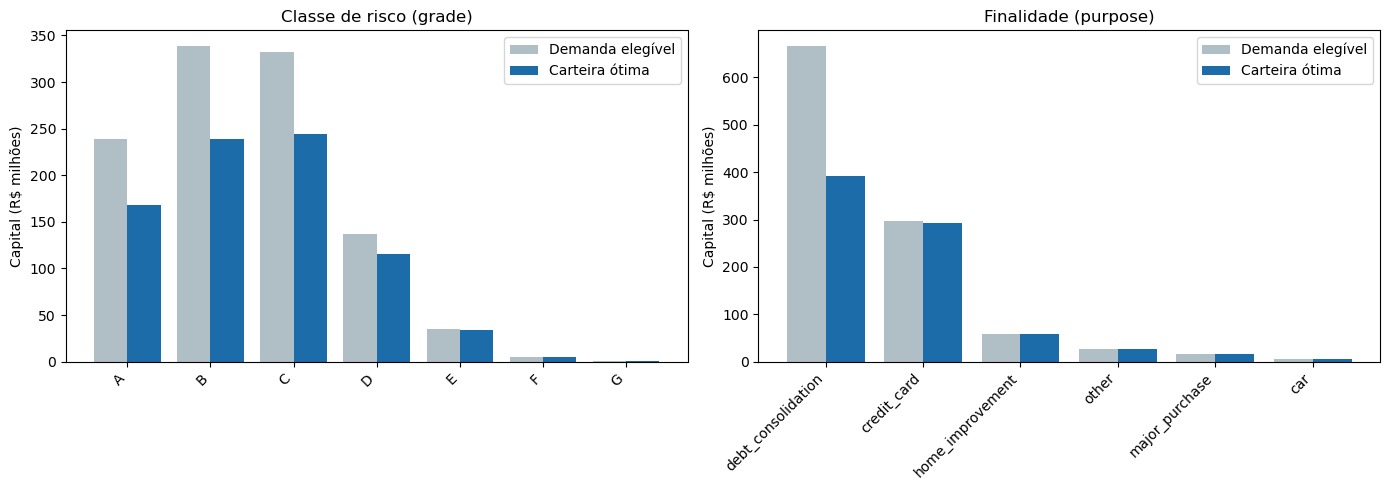

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, dim, titulo in zip(axes, ['grade', 'purpose'], ['Classe de risco (grade)', 'Finalidade (purpose)']):
    dem = clientes.groupby(dim)['loan_amnt'].sum()
    car = carteira.groupby(dim)['loan_amnt'].sum().reindex(dem.index).fillna(0)
    if dim == 'purpose':
        top = dem.sort_values(ascending=False).head(6).index
        dem, car = dem.reindex(top), car.reindex(top)
    pos = np.arange(len(dem)); w = 0.4
    ax.bar(pos - w/2, dem/1e6, w, label='Demanda elegível', color='#B0BEC5')
    ax.bar(pos + w/2, car/1e6, w, label='Carteira ótima', color='#1B6CA8')
    ax.set_xticks(pos); ax.set_xticklabels(dem.index, rotation=45, ha='right')
    ax.set_title(titulo); ax.set_ylabel('Capital (R$ milhões)'); ax.legend()
plt.tight_layout(); plt.show()

# 11. EXPORTAÇÃO DA CARTEIRA SELECIONADA

Por fim, exportamos a carteira ótima com os campos relevantes para registro e auditoria da decisão: o identificador do contrato, suas condições, o risco estimado e a contribuição esperada ao resultado.

In [19]:
cols = ['id_cliente', 'loan_amnt', 'int_rate', 'term', 'grade', 'purpose',
        'PD', 'score', 'juros', 'lucro_esp']
carteira_final = carteira[cols].sort_values('lucro_esp', ascending=False).reset_index(drop=True)
carteira_final.to_parquet('dados/carteira_otima.parquet')
print(f'Carteira ótima exportada: {len(carteira_final):,} contratos.')
carteira_final.head(10)

Carteira ótima exportada: 50,282 contratos.


,id_cliente,loan_amnt,int_rate,term,grade,purpose,PD,score,juros,lucro_esp
0,391793,35000,25.99,60,G,credit_card,0.09,511.16,"27,862.60","22,196.45"
1,395373,35000,24.99,60,F,house,0.09,509.73,"26,626.00","20,944.91"
2,376167,35000,25.99,60,G,debt_consolidation,0.12,494.58,"27,862.60","20,531.20"
3,433397,35000,24.99,60,F,debt_consolidation,0.11,501.38,"26,626.00","20,153.32"
4,394776,35000,25.57,60,F,debt_consolidation,0.12,493.77,"27,341.80","19,980.03"
5,464481,35000,23.99,60,F,debt_consolidation,0.09,508.39,"25,400.80","19,714.62"
6,417578,35000,25.80,60,G,debt_consolidation,0.13,487.86,"27,626.80","19,536.71"
7,450279,35000,24.08,60,F,debt_consolidation,0.10,504.55,"25,510.60","19,461.37"
8,398541,35000,24.50,60,F,debt_consolidation,0.11,498.26,"26,024.20","19,297.58"
9,462636,35000,24.99,60,F,debt_consolidation,0.12,490.91,"26,626.00","19,025.09"


# 12. CONCLUSÃO

A etapa de otimização completa o pipeline *predict-then-optimize*. A partir das probabilidades de default estimadas pelo scorecard, formulamos e resolvemos um programa linear inteiro binário que seleciona, entre os contratos elegíveis, a carteira de maior lucro esperado sujeita a limites de capital, de risco médio e de concentração.

O resultado não é apenas uma lista de empréstimos aprovados, mas uma política de concessão transparente e auditável: cada decisão decorre de um critério explícito de otimização, e a análise das restrições ativas e do preço-sombra do capital oferece à gestão uma leitura direta de onde estão as restrições que limitam o resultado e de quanto valeria relaxá-las. A comparação com políticas ingênuas quantifica o ganho de ordenar a decisão por um modelo de otimização em vez de regras simples de priorização.